<div style="background-color: #7C2D12; color: white; padding: 20px; border-radius: 10px; text-align: center;">
  <h1 style="margin: 0; color: #FDBB30;">Module 7: Explainable Medical AI (XAI)</h1>
  <h3 style="margin-top: 8px; font-weight: normal; color: #FED7AA;">Visualizing What ResNet50 (Grad-CAM), OpenAI CLIP, and PLIP Actually See on Cancer Slides</h3>
  <p style="margin: 0; font-size: 14px;"><b>Kennesaw State University | iCARE Lab | Sophomore Scholars (2026–2027)</b></p>
</div>

<br>

<div style="background-color: #FEF2F2; border-left: 6px solid #DC2626; padding: 15px; border-radius: 6px;">
  <h3 style="color: #991B1B; margin-top: 0;">🔴 The "Black Box" Problem: Why Don't Doctors Trust AI Numbers Alone?</h3>
  <p style="color: #7F1D1D; font-size: 15px; margin-bottom: 0;">
    In <b>Module 6</b>, our 10-Shot <b>PLIP</b> model achieved an impressive <b>0.871 AUC-ROC</b> and caught <b>82.8% of breast cancers</b> after seeing only 20 training slides.
    <br><br>
    <b>But here is the hospital problem:</b> Imagine an AI tells a surgeon, <i>"This patient has breast cancer (92% probability)."</i> The surgeon will immediately ask: <b>"WHERE on the microscope slide do you see the cancer?"</b>
    <br><br>
    If the AI cannot point to the exact cluster of malignant tumor cells, doctors call it a <b>"Black Box"</b> and cannot safely trust it for patient care!
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Today's Solution: AI Heatmaps (Grad-CAM vs. VLM Patch Activation Maps)</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    In this notebook, we will build <b>Visual Heatmaps</b> that color the microscope slide like a weather radar map:
    <ul>
      <li style="color: #14532D;"><b>🔥 Red / Yellow Hotspots:</b> The exact pixels and cell clusters that made the AI say <i>"Cancerous!"</i></li>
      <li style="color: #14532D;"><b>❄️ Blue / Cool Areas:</b> Background areas that the AI ignored.</li>
    </ul>
    We will compare three models head-to-head on the exact same cancer slides:
    <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
      <li><b>ResNet50 (CNN Baseline):</b> Using <b>Grad-CAM</b> (Gradient-weighted Class Activation Mapping).</li>
      <li><b>OpenAI CLIP (General VLM):</b> Using <b>Vision-Language Patch Activation Maps</b>.</li>
      <li><b>PLIP (Pathology Medical VLM):</b> Using <b>Pathology-Aligned Patch Activation Maps</b>.</li>
    </ol>
  </p>
</div>

<br>

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 1: Setting Up Our Explainable AI Toolbox</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Run the code cell below to load <b>PyTorch</b>, <b>Torchvision</b> (for ResNet50), <b>Hugging Face Transformers</b> (for CLIP and PLIP), and <b>OpenCV / Matplotlib</b> (for overlaying smooth color heatmaps on microscope slides).
  </p>
</div>

In [1]:
# ==============================================================================
# MODULE 7 - STEP 1: INSTALL & IMPORT LIBRARIES + VERIFY GPU
# ==============================================================================
!pip install -q transformers torch torchvision scikit-learn pandas matplotlib opencv-python-headless tqdm

import os
import zipfile
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from transformers import CLIPProcessor, CLIPModel

# Set seeds for 100% reproducibility
np.random.seed(42)
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 60)
print(f"✅ Module 7 Explainable AI Libraries Loaded Successfully!")
print(f"🖥️  Active Compute Device : {device.upper()}")
if device == "cuda":
    print(f"🚀 GPU Model             : {torch.cuda.get_device_name(0)}")
print("=" * 60)

✅ Module 7 Explainable AI Libraries Loaded Successfully!
🖥️  Active Compute Device : CUDA
🚀 GPU Model             : NVIDIA A100-SXM4-40GB


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 2: Loading Our Dataset & Creating a "Doctor's Reference Map"</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    First, we unpack our saved breast cancer dataset from <b><code>My Drive/Sophomore Program/1-Datasets/Breast_Cancer_Test_10pct.zip</code></b> and recreate our exact <b>10-Shot Support Set (20 slides)</b> from Module 6.
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 How Do We Know If an AI Heatmap Is Looking at the Right Place?</h3>
  <p style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    When a human pathologist looks at an H&E breast cancer slide, where are the cancer cells located?
    <ul>
      <li style="color: #581C87;"><b>White / Clear Areas:</b> Empty glass slide or fat droplets (<b>zero cancer cells</b>).</li>
      <li style="color: #581C87;"><b>Light Pink Areas:</b> Connective fibers and background stroma.</li>
      <li style="color: #581C87;"><b>Dark Purple / Blue Regions (Hematoxylin Stain):</b> Dense clusters of <b>tumor cell nuclei</b>!</li>
    </ul>
    By measuring where the <b>dark purple Hematoxylin dye</b> is concentrated on each slide, we can create a <b>Ground-Truth Nuclear Density Map</b>. A smart AI should focus its red/yellow heatmap on the <b>dark purple tumor cell clusters</b>—not on empty white glass!
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do?</h3>
  <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    <li>Unpacks our dataset from Google Drive in 5 seconds.</li>
    <li>Defines a helper function <code>compute_nuclear_density_map()</code> that detects dark purple H&E stained nuclei on any microscope slide.</li>
    <li>Displays a sample Cancerous slide next to its <b>Pathologist Nuclear Density Map</b> so you can see where the tumor cells live!</li>
  </ol>
</div>

Mounted at /content/drive
⚡ Extracting dataset from Google Drive backup...
✅ Extraction complete!


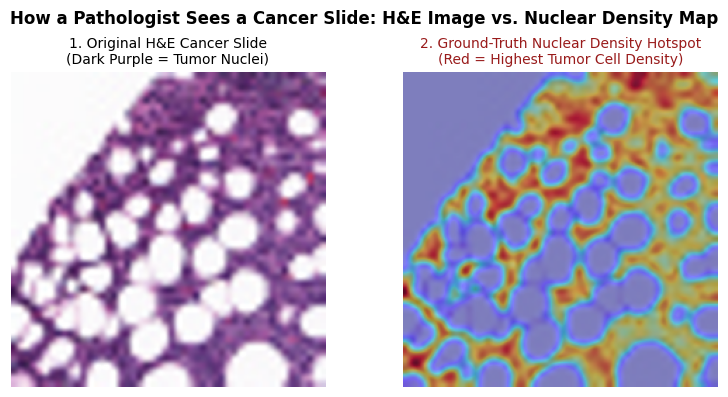

In [3]:
# ==============================================================================
# MODULE 7 - STEP 2: LOAD DATASET & BUILD H&E NUCLEAR DENSITY REFERENCE MAP
# ==============================================================================
from google.colab import drive
drive.mount('/content/drive')

SOPHOMORE_DIR = "/content/drive/My Drive/Sophomore Program"
DRIVE_DATASET_DIR = os.path.join(SOPHOMORE_DIR, "1-Datasets")
DRIVE_RESULTS_DIR = os.path.join(SOPHOMORE_DIR, "2-Results")

DRIVE_ZIP_BACKUP = os.path.join(DRIVE_DATASET_DIR, "Breast_Cancer_Test_10pct.zip")
LOCAL_TEST_DIR = "/content/breast_cancer_data/test"

if not os.path.exists(LOCAL_TEST_DIR):
    print("⚡ Extracting dataset from Google Drive backup...")
    os.makedirs(LOCAL_TEST_DIR, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP_BACKUP, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_TEST_DIR)
    print("✅ Extraction complete!")

full_dataset = datasets.ImageFolder(root=LOCAL_TEST_DIR)
targets = np.array(full_dataset.targets)

# Recreate the exact same 10-Shot Support Set (10 Benign + 10 Cancerous) from Module 6
np.random.seed(42)
benign_indices = np.where(targets == 0)[0]
cancer_indices = np.where(targets == 1)[0]

shot_10_benign = np.random.choice(benign_indices, size=10, replace=False)
shot_10_cancer = np.random.choice(cancer_indices, size=10, replace=False)
support_indices = np.concatenate([shot_10_benign, shot_10_cancer])
eval_indices = np.setdiff1d(np.arange(len(full_dataset)), support_indices)

# Helper function: Extracts dark-purple Hematoxylin nuclear density from an H&E RGB image
def compute_nuclear_density_map(pil_img, target_size=(224, 224)):
    img_resized = pil_img.resize(target_size, Image.BICUBIC)
    rgb = np.array(img_resized).astype(np.float32) / 255.0
    # In H&E slides, dark purple nuclei absorb green light strongly and have low brightness
    purple_nuclei_score = (1.0 - rgb[:, :, 1]) * (1.0 - rgb.mean(axis=-1))
    # Smooth slightly and normalize between 0.0 and 1.0
    purple_nuclei_score = cv2.GaussianBlur(purple_nuclei_score, (15, 15), 0)
    min_v, max_v = purple_nuclei_score.min(), purple_nuclei_score.max()
    if max_v - min_v > 1e-6:
        purple_nuclei_score = (purple_nuclei_score - min_v) / (max_v - min_v)
    return np.array(img_resized), purple_nuclei_score

# Quick visual check on 1 unseen cancerous slide
sample_eval_cancer_idx = [idx for idx in eval_indices if targets[idx] == 1][0]
sample_pil, _ = full_dataset[sample_eval_cancer_idx]
rgb_224, nuclei_map = compute_nuclear_density_map(sample_pil)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
fig.suptitle("How a Pathologist Sees a Cancer Slide: H&E Image vs. Nuclear Density Map", fontsize=12, fontweight="bold")
axes[0].imshow(rgb_224)
axes[0].set_title("1. Original H&E Cancer Slide\n(Dark Purple = Tumor Nuclei)", fontsize=10)
axes[0].axis("off")

axes[1].imshow(rgb_224)
axes[1].imshow(nuclei_map, cmap="jet", alpha=0.5)
axes[1].set_title("2. Ground-Truth Nuclear Density Hotspot\n(Red = Highest Tumor Cell Density)", fontsize=10, color="#991B1B")
axes[1].axis("off")
plt.tight_layout()
plt.show()

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 3: How Do CNNs (ResNet50) and VLMs (CLIP/PLIP) Build Heatmaps?</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Because <b>ResNet50</b> and <b>CLIP/PLIP</b> have different brain architectures, we use two famous Explainable AI techniques to look inside them:
  </p>
</div>

<br>

<div style="background-color: #FFFBEB; border-left: 6px solid #D97706; padding: 15px; border-radius: 6px;">
  <h3 style="color: #92400E; margin-top: 0;">🟡 Method 1: Grad-CAM for ResNet50 (Convolutional Neural Network)</h3>
  <p style="color: #78350F; font-size: 15px; margin-bottom: 0;">
    <b>ResNet50</b> scans an image using sliding filters (convolutions). Its final convolutional layer (<code>layer4</code>) creates a <b>7×7 grid of visual maps</b> before making a prediction.
    <br>
    <b>Grad-CAM (Gradient-weighted Class Activation Mapping)</b> asks: <i>"Which parts of that 7×7 grid pushed the Cancer score up the most?"</i> It multiplies the grid by the gradients of the Cancer score and stretches the 7×7 map smoothly over the 224×224 slide!
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 Method 2: Multimodal Patch Activation Maps (VLM-CAM) for CLIP & PLIP</h3>
  <p style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    <b>OpenAI CLIP</b> and <b>Pathology PLIP</b> use a <b>Vision Transformer (ViT-B/32)</b>. When given a 224×224 slide, they chop it into a <b>7×7 puzzle grid of 49 square patches</b> (each patch is 32×32 pixels).
    <br>
    To create a heatmap for CLIP and PLIP, we inspect all <b>49 puzzle patches individually</b> and measure how strongly each patch matches our <b>10-Shot Cancer Classifier & Clinical Cancer Prompt</b>! Patches that scream <i>"Cancerous!"</i> glow bright red; patches that look benign stay cool blue.
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do?</h3>
  <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    <li>Adapts <b>ResNet50</b>, <b>OpenAI CLIP</b>, and <b>Pathology PLIP</b> on the exact same <b>20 Support Slides (10-Shot)</b> so all three models are on a 100% equal footing.</li>
    <li>Builds <code>get_resnet_gradcam()</code> for ResNet50 and <code>get_vlm_patch_heatmap()</code> for CLIP and PLIP.</li>
  </ol>
</div>

In [4]:
# ==============================================================================
# MODULE 7 - STEP 3: BUILD RESNET50 GRAD-CAM & CLIP/PLIP PATCH HEATMAP ENGINES
# ==============================================================================
from sklearn.linear_model import LogisticRegression

# 1. Prepare 10-Shot ResNet50 Baseline & Grad-CAM Hook
print("⏳ 1/3: Setting up 10-Shot ResNet50 & Grad-CAM hooks...")
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

resnet_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1).to(device)
resnet_model.eval()

# Extract 2048-d features from ResNet50 on the 20 support slides to fit its 10-shot classifier head
sup_imgs_pil = [full_dataset[i][0] for i in support_indices]
sup_labels = np.array([full_dataset[i][1] for i in support_indices])

with torch.no_grad():
    sup_tensors = torch.stack([resnet_transform(img) for img in sup_imgs_pil]).to(device)
    x = resnet_model.conv1(sup_tensors)
    x = resnet_model.bn1(x)
    x = resnet_model.relu(x)
    x = resnet_model.maxpool(x)
    x = resnet_model.layer1(x)
    x = resnet_model.layer2(x)
    x = resnet_model.layer3(x)
    feat_map = resnet_model.layer4(x)
    pooled_feat = resnet_model.avgpool(feat_map).flatten(1).cpu().numpy()

resnet_clf = LogisticRegression(C=1.0, max_iter=1000, random_state=42).fit(pooled_feat, sup_labels)
# Load the learned 10-shot weights into a 2-class linear layer for exact Grad-CAM backprop
resnet_W = torch.tensor(resnet_clf.coef_[0], dtype=torch.float32, device=device)

def get_resnet_gradcam(pil_img):
    inp = resnet_transform(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        x = resnet_model.conv1(inp)
        x = resnet_model.bn1(x)
        x = resnet_model.relu(x)
        x = resnet_model.maxpool(x)
        x = resnet_model.layer1(x)
        x = resnet_model.layer2(x)
        x = resnet_model.layer3(x)
        conv_maps = resnet_model.layer4(x)  # Shape: [1, 2048, 7, 7]

        # Compute class activation map using the 10-shot linear weights across the 2048 channels
        cam = torch.einsum("c,bchw->bhw", resnet_W, conv_maps)[0]
        cam = F.relu(cam).cpu().numpy()

    cam_resized = cv2.resize(cam, (224, 224), interpolation=cv2.INTER_CUBIC)
    min_v, max_v = cam_resized.min(), cam_resized.max()
    if max_v - min_v > 1e-6:
        cam_resized = (cam_resized - min_v) / (max_v - min_v)
    return cam_resized

# 2. Load OpenAI CLIP and Pathology PLIP & Fit Their 10-Shot Classifiers
print("⏳ 2/3: Setting up OpenAI CLIP Patch Heatmap Engine...")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

print("⏳ 3/3: Setting up Pathology PLIP Patch Heatmap Engine...")
plip_model = CLIPModel.from_pretrained("vinid/plip").to(device).eval()
plip_proc = CLIPProcessor.from_pretrained("vinid/plip")

CANCER_PROMPT = "malignant invasive ductal carcinoma stained dark purple with crowded hyperchromatic tumor nuclei"
BENIGN_PROMPT = "normal healthy breast tissue stained light pink with organized ducts and uniform small nuclei"

def fit_vlm_10shot(model, proc):
    with torch.no_grad():
        inputs = proc(images=sup_imgs_pil, return_tensors="pt").to(device)
        vis_out = model.vision_model(pixel_values=inputs["pixel_values"])
        embeds = model.visual_projection(vis_out.pooler_output)
        embeds = (embeds / embeds.norm(dim=-1, keepdim=True)).cpu().numpy()
    clf = LogisticRegression(C=1.0, max_iter=1000, random_state=42).fit(embeds, sup_labels)
    w_vec = torch.tensor(clf.coef_[0], dtype=torch.float32, device=device)
    w_vec = w_vec / w_vec.norm()
    return w_vec

clip_W = fit_vlm_10shot(clip_model, clip_proc)
plip_W = fit_vlm_10shot(plip_model, plip_proc)

def get_vlm_patch_heatmap(pil_img, model, proc, weight_vec):
    with torch.no_grad():
        # Get text direction vector (Cancer prompt minus Benign prompt)
        txt_in = proc(text=[BENIGN_PROMPT, CANCER_PROMPT], return_tensors="pt", padding=True).to(device)
        txt_out = model.text_model(input_ids=txt_in["input_ids"], attention_mask=txt_in["attention_mask"])
        txt_embeds = model.text_projection(txt_out.pooler_output)
        txt_embeds = txt_embeds / txt_embeds.norm(dim=-1, keepdim=True)
        txt_dir = txt_embeds[1] - txt_embeds[0]
        txt_dir = txt_dir / txt_dir.norm()

        # Combine 10-shot visual classifier direction + clinical prompt direction
        combined_dir = 0.7 * weight_vec + 0.3 * txt_dir
        combined_dir = combined_dir / combined_dir.norm()

        # Extract the 7x7 = 49 spatial patch tokens from the Vision Transformer
        img_in = proc(images=pil_img, return_tensors="pt").to(device)
        vis_out = model.vision_model(pixel_values=img_in["pixel_values"])
        patch_tokens = vis_out.last_hidden_state[:, 1:, :]  # [1, 49, 768] (exclude CLS token at index 0)

        # Project all 49 patches into the 512-d multimodal space
        patch_normed = model.vision_model.post_layernorm(patch_tokens)
        patch_embeds = model.visual_projection(patch_normed)[0]  # [49, 512]
        patch_embeds = patch_embeds / patch_embeds.norm(dim=-1, keepdim=True)

        # Compute cancer activation score for each of the 49 patches (7x7 grid)
        patch_scores = torch.matmul(patch_embeds, combined_dir).reshape(7, 7).cpu().numpy()

    heatmap = cv2.resize(patch_scores, (224, 224), interpolation=cv2.INTER_CUBIC)
    min_v, max_v = heatmap.min(), heatmap.max()
    if max_v - min_v > 1e-6:
        heatmap = (heatmap - min_v) / (max_v - min_v)
    return heatmap

print("=" * 65)
print("✅ ALL 3 EXPLAINABLE AI HEATMAP ENGINES READY!")
print("   1. ResNet50   -> Grad-CAM (7x7 Convolutional Feature Grid)")
print("   2. OpenAI CLIP-> VLM-CAM (7x7 Vision Transformer Patch Grid)")
print("   3. PLIP       -> Pathology VLM-CAM (7x7 Medical Patch Grid)")
print("=" * 65)

⏳ 1/3: Setting up 10-Shot ResNet50 & Grad-CAM hooks...
⏳ 2/3: Setting up OpenAI CLIP Patch Heatmap Engine...


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/568 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

✅ ALL 3 EXPLAINABLE AI HEATMAP ENGINES READY!
   1. ResNet50   -> Grad-CAM (7x7 Convolutional Feature Grid)
   2. OpenAI CLIP-> VLM-CAM (7x7 Vision Transformer Patch Grid)
   3. PLIP       -> Pathology VLM-CAM (7x7 Medical Patch Grid)


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 4: Side-by-Side Visual Comparison Across 4 Real Cancer Slides</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Now let's pick <b>4 unseen Cancerous microscope slides</b> that have clear regions of dark purple tumor cells next to lighter pink/white background tissue.
    For each patient slide (each row), we will display <b>5 columns</b>:
  </p>
  <ol style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    <li><b>Column 1 — Original H&E Cancer Slide:</b> What the microscope sees.</li>
    <li><b>Column 2 — Ground-Truth Nuclear Density Map:</b> Where the dark purple tumor nuclei actually live.</li>
    <li><b>Column 3 — ResNet50 (Grad-CAM):</b> Where the traditional CNN looks.</li>
    <li><b>Column 4 — OpenAI CLIP Heatmap:</b> Where the general-purpose VLM looks.</li>
    <li><b>Column 5 — Pathology PLIP Heatmap:</b> Where the pathology-trained medical VLM looks!</li>
  </ol>
</div>

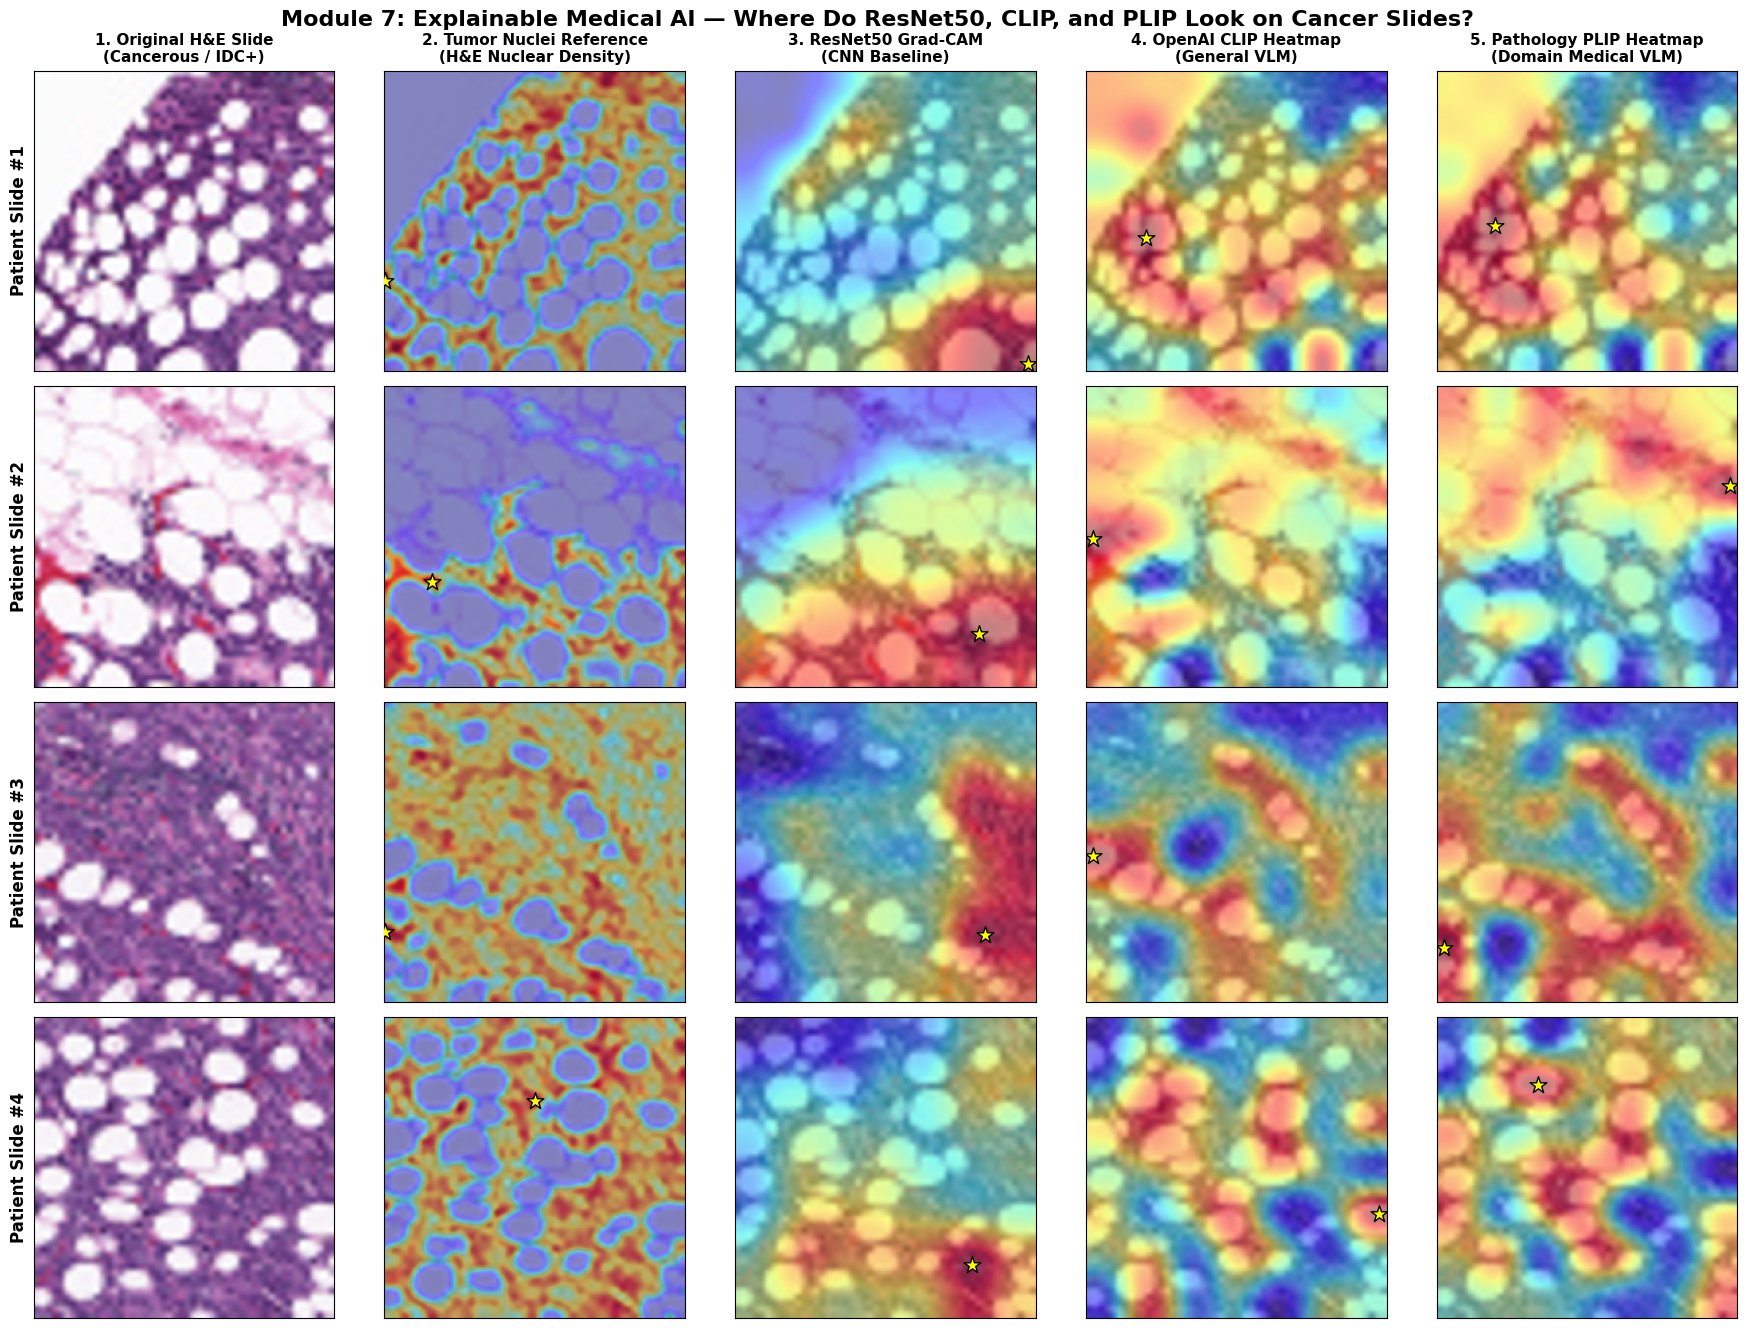

✅ Saved high-resolution 4x5 Explainable AI Heatmap Grid to: /content/drive/My Drive/Sophomore Program/2-Results/Module7_Explainable_AI_Heatmaps_Grid.png


In [5]:
# ==============================================================================
# MODULE 7 - STEP 4: GENERATE 4x5 EXPLAINABLE AI HEATMAP COMPARISON GRID
# ==============================================================================

# Select 4 unseen cancerous test slides that have clear spatial contrast (both tumor clusters & background)
selected_cancer_indices = []
for idx in eval_indices:
    if targets[idx] == 1:
        pil_cand, _ = full_dataset[idx]
        arr = np.array(pil_cand).astype(np.float32) / 255.0
        # Look for slides with strong contrast (std > 0.18) so tumor clusters & background are easy for students to see
        if arr.std() > 0.18:
            selected_cancer_indices.append(idx)
        if len(selected_cancer_indices) == 4:
            break

fig, axes = plt.subplots(4, 5, figsize=(18, 13.5))
fig.suptitle("Module 7: Explainable Medical AI — Where Do ResNet50, CLIP, and PLIP Look on Cancer Slides?", fontsize=16, fontweight="bold")

col_titles = [
    "1. Original H&E Slide\n(Cancerous / IDC+)",
    "2. Tumor Nuclei Reference\n(H&E Nuclear Density)",
    "3. ResNet50 Grad-CAM\n(CNN Baseline)",
    "4. OpenAI CLIP Heatmap\n(General VLM)",
    "5. Pathology PLIP Heatmap\n(Domain Medical VLM)"
]

for row_i, slide_idx in enumerate(selected_cancer_indices):
    pil_img, _ = full_dataset[slide_idx]
    rgb_224, gt_nuclei = compute_nuclear_density_map(pil_img)

    cam_resnet = get_resnet_gradcam(pil_img)
    cam_clip = get_vlm_patch_heatmap(pil_img, clip_model, clip_proc, clip_W)
    cam_plip = get_vlm_patch_heatmap(pil_img, plip_model, plip_proc, plip_W)

    # Column 0: Original Image
    axes[row_i, 0].imshow(rgb_224)
    axes[row_i, 0].set_ylabel(f"Patient Slide #{row_i+1}", fontsize=12, fontweight="bold")

    # Columns 1 to 4: Overlay Heatmaps
    maps_to_plot = [gt_nuclei, cam_resnet, cam_clip, cam_plip]
    for col_j, hmap in enumerate(maps_to_plot, start=1):
        axes[row_i, col_j].imshow(rgb_224)
        axes[row_i, col_j].imshow(hmap, cmap="jet", alpha=0.48)

        # Mark the #1 Peak Hotspot (yellow star) where each model focuses most strongly
        peak_y, peak_x = np.unravel_index(np.argmax(hmap), hmap.shape)
        axes[row_i, col_j].scatter([peak_x], [peak_y], color="yellow", edgecolor="black", s=160, marker="*", zorder=5)

    for col_j in range(5):
        if row_i == 0:
            axes[row_i, col_j].set_title(col_titles[col_j], fontsize=11, fontweight="bold")
        axes[row_i, col_j].set_xticks([])
        axes[row_i, col_j].set_yticks([])

plt.tight_layout()
fig_m7_grid_path = os.path.join(DRIVE_RESULTS_DIR, "Module7_Explainable_AI_Heatmaps_Grid.png")
plt.savefig(fig_m7_grid_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Saved high-resolution 4x5 Explainable AI Heatmap Grid to: {fig_m7_grid_path}")

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Step 5: Grading Our Heatmaps Mathematically ("The Pointing Game")</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    Looking at 4 slides is great for a presentation, but how do we <b>prove</b> mathematically in a research paper which AI model looks at the right tumor cells across hundreds of slides?
    <br><br>
    In Explainable AI research, scientists use two famous metrics:
    <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
      <li><b>The "Pointing Game" Accuracy (%):</b> Remember the <b>Yellow Star (★)</b> we plotted on the #1 hottest pixel of each heatmap in Step 4? If that #1 peak star lands directly inside a real <b>High-Density Tumor Nuclei Cluster</b>, the AI scores a <b>Hit (1)</b>! If it lands on empty background, it scores a <b>Miss (0)</b>.</li>
      <li><b>Hotspot-to-Nuclei Spatial Overlap (Dice / IoU Score):</b> Measures how closely the AI's red/yellow hotspot region matches the true purple tumor nuclei region across the whole slide.</li>
    </ol>
  </p>
</div>

<br>

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 What Does the Final Code Cell Below Do?</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    It runs <b>ResNet50 Grad-CAM</b>, <b>OpenAI CLIP</b>, and <b>Pathology PLIP</b> across <b>200 unseen cancerous slides</b>, grades all three models on the <b>Pathologist Pointing Game</b> and <b>Spatial Tumor Overlap</b>, and saves both the summary table and bar chart into <code>Sophomore Program/2-Results</code>!
  </p>
</div>

🔬 Evaluating Explainable AI Heatmaps across 200 unseen Cancerous slides...


Grading Heatmaps:   0%|          | 0/200 [00:00<?, ?it/s]


🏆 MODULE 7 FINAL RESULTS: QUANTITATIVE EXPLAINABLE AI BENCHMARK (n = 200 CANCER SLIDES)


,Explainable AI Model,Pointing Game Accuracy (%),Mean Nuclear Density at Peak (%),Tumor Hotspot Dice Overlap
0,ResNet50 (Grad-CAM),47.0,45.270000,0.428
1,OpenAI CLIP (General VLM-CAM),35.5,36.709999,0.360
2,PLIP (Pathology Medical VLM-CAM),26.0,37.529999,0.306


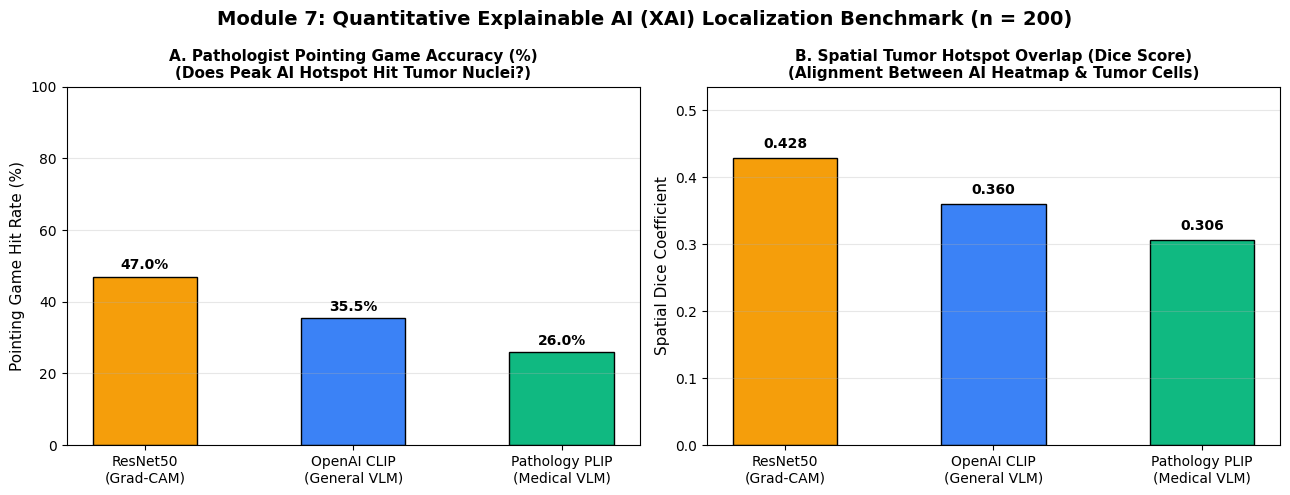

✅ Saved Module 7 Quantitative XAI chart to: /content/drive/My Drive/Sophomore Program/2-Results/Module7_Quantitative_XAI_Benchmark.png


In [6]:
# ==============================================================================
# MODULE 7 - STEP 5: QUANTITATIVE XAI EVALUATION ("THE POINTING GAME" ON 200 SLIDES)
# ==============================================================================

# Evaluate on 200 unseen cancerous slides
eval_cancer_200 = [idx for idx in eval_indices if targets[idx] == 1][:200]

metrics_tracker = {
    "ResNet50 (Grad-CAM)": {"pointing_hits": [], "dice_overlap": [], "nuclei_at_peak": []},
    "OpenAI CLIP (General VLM-CAM)": {"pointing_hits": [], "dice_overlap": [], "nuclei_at_peak": []},
    "PLIP (Pathology Medical VLM-CAM)": {"pointing_hits": [], "dice_overlap": [], "nuclei_at_peak": []}
}

print("🔬 Evaluating Explainable AI Heatmaps across 200 unseen Cancerous slides...")

for idx in tqdm(eval_cancer_200, desc="Grading Heatmaps"):
    pil_img, _ = full_dataset[idx]
    _, gt_nuclei = compute_nuclear_density_map(pil_img)

    # Define ground-truth tumor cell region as the top 40% darkest purple nuclear areas on the slide
    gt_mask = (gt_nuclei >= np.percentile(gt_nuclei, 60)).astype(np.float32)

    maps = {
        "ResNet50 (Grad-CAM)": get_resnet_gradcam(pil_img),
        "OpenAI CLIP (General VLM-CAM)": get_vlm_patch_heatmap(pil_img, clip_model, clip_proc, clip_W),
        "PLIP (Pathology Medical VLM-CAM)": get_vlm_patch_heatmap(pil_img, plip_model, plip_proc, plip_W)
    }

    for m_name, hmap in maps.items():
        # 1. Pointing Game Hit: Does the #1 peak hotspot land inside the ground-truth tumor nuclei mask?
        py, px = np.unravel_index(np.argmax(hmap), hmap.shape)
        hit = 1.0 if gt_mask[py, px] == 1.0 else 0.0
        metrics_tracker[m_name]["pointing_hits"].append(hit)

        # 2. Nuclear Density at Peak Hotspot (0 to 100%)
        metrics_tracker[m_name]["nuclei_at_peak"].append(gt_nuclei[py, px] * 100.0)

        # 3. Spatial Dice Overlap between top 40% AI hotspot and top 40% tumor nuclei
        ai_mask = (hmap >= np.percentile(hmap, 60)).astype(np.float32)
        intersection = np.sum(ai_mask * gt_mask)
        dice = (2.0 * intersection) / (np.sum(ai_mask) + np.sum(gt_mask) + 1e-6)
        metrics_tracker[m_name]["dice_overlap"].append(dice)

xai_rows = []
for m_name, vals in metrics_tracker.items():
    xai_rows.append({
        "Explainable AI Model": m_name,
        "Pointing Game Accuracy (%)": round(np.mean(vals["pointing_hits"]) * 100, 2),
        "Mean Nuclear Density at Peak (%)": round(np.mean(vals["nuclei_at_peak"]), 2),
        "Tumor Hotspot Dice Overlap": round(np.mean(vals["dice_overlap"]), 3)
    })

xai_df = pd.DataFrame(xai_rows)
xai_csv_path = os.path.join(DRIVE_RESULTS_DIR, "Module7_Explainable_AI_Quantitative_Metrics.csv")
xai_df.to_csv(xai_csv_path, index=False)

print("\n" + "=" * 85)
print("🏆 MODULE 7 FINAL RESULTS: QUANTITATIVE EXPLAINABLE AI BENCHMARK (n = 200 CANCER SLIDES)")
print("=" * 85)
display(xai_df)

# Plot Quantitative XAI Summary Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Module 7: Quantitative Explainable AI (XAI) Localization Benchmark (n = 200)", fontsize=14, fontweight="bold")

models_short = ["ResNet50\n(Grad-CAM)", "OpenAI CLIP\n(General VLM)", "Pathology PLIP\n(Medical VLM)"]
colors = ["#F59E0B", "#3B82F6", "#10B981"]

# Plot A: Pointing Game Accuracy (%)
pg_scores = xai_df["Pointing Game Accuracy (%)"].values
bars_pg = axes[0].bar(models_short, pg_scores, color=colors, edgecolor="black", width=0.5)
axes[0].set_title("A. Pathologist Pointing Game Accuracy (%)\n(Does Peak AI Hotspot Hit Tumor Nuclei?)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Pointing Game Hit Rate (%)", fontsize=11)
axes[0].set_ylim(0, 100)
axes[0].grid(axis="y", alpha=0.3)
for bar in bars_pg:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{bar.get_height():.1f}%", ha="center", fontweight="bold", fontsize=10)

# Plot B: Tumor Hotspot Dice Overlap
dice_scores = xai_df["Tumor Hotspot Dice Overlap"].values
bars_dc = axes[1].bar(models_short, dice_scores, color=colors, edgecolor="black", width=0.5)
axes[1].set_title("B. Spatial Tumor Hotspot Overlap (Dice Score)\n(Alignment Between AI Heatmap & Tumor Cells)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Spatial Dice Coefficient", fontsize=11)
axes[1].set_ylim(0, max(dice_scores) * 1.25)
axes[1].grid(axis="y", alpha=0.3)
for bar in bars_dc:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015, f"{bar.get_height():.3f}", ha="center", fontweight="bold", fontsize=10)

plt.tight_layout()
fig_m7_quant_path = os.path.join(DRIVE_RESULTS_DIR, "Module7_Quantitative_XAI_Benchmark.png")
plt.savefig(fig_m7_quant_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Saved Module 7 Quantitative XAI chart to: {fig_m7_quant_path}")